# Case Study 1 : Collecting Data from NewsAPI

Due Date: 11/10/2026, **BEFORE the beginning of class at 12:00pm EST**

## **NOTE: There are *always* last minute issues submitting the case studies.  DO NOT WAIT UNTIL THE LAST MINUTE!**

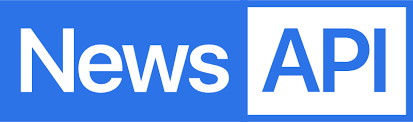

**TEAM Members:** Please EDIT this cell and add the names of all the team members in your team

    Luke Frauton
    
    Andrew Knight
    
    Brooke Colleran

**Suggested Readings:**
* The NewsAPI documentation: https://newsapi.org/docs
* The Python library for NewsAPI: https://newsapi.org/docs/client-libraries/python
* The Python notebook I used in class 3
  * In fact, it is intentional that many of these questions can be answered directly from there (except for question 4)!
* The idea is to ease you into the case studies :-)

**Don't forget!**
* You will need to install the newsapi-python library to access NewsAPI
 * pip install newsapi-python
* You will need to get an API key from NewsAPI to access the data
  * https://newsapi.org/register


** NOTE **
* **Please don't forget to save the notebook frequently when working in IPython Notebook, otherwise the changes you made can be lost**.

# Problem 1 (20 points): Sampling NewsAPI data on a certain topic

* Select a topic that you are interested in, for example, "WPI" or "Lady Gaga"
* Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000.)
* Store the articles you downloaded in a file on Google Drive (txt file or json file)

In [123]:
! pip install newsapi-python

In [124]:
from newsapi import NewsApiClient

# See https://newsapi.org/docs for more information
# on NewsAPI implementation.

API_KEY = '55a91a2a686049b58636db4c9a461f4b'

newsapi = NewsApiClient(api_key=API_KEY)
print(newsapi)

In [125]:
#  Set this variable to a trending topic,
# or anything else for that matter. The example query below
# was a trending topic when this content was being developed
# and is used throughout the remainder of this chapter.

q = 'Football'

articles_1 = newsapi.get_everything(q=q,
                                    from_param='2026-10-11',
                                    to='2026-10-21',
                                    language='en',
                                    sort_by='relevancy',
                                    page=5
                                    )
articles_2 = newsapi.get_everything(q=q,
                                    from_param='2026-10-21',
                                    to='2026-10-31',
                                    language='en',
                                    sort_by='relevancy',
                                    page=5
                                    )
articles_3 = newsapi.get_everything(q=q,
                                    from_param='2026-10-31',
                                    to='2026-11-11',
                                    language='en',
                                    sort_by='relevancy',
                                    page=5
                                    )

all_articles_list = (
    articles_1.get('articles', []) +
    articles_2.get('articles', []) +
    articles_3.get('articles', [])
)

data = json.dumps(all_articles_list, indent=1)

file = open('gdrive/MyDrive/ds3010_2026/CaseStudy1.txt','w')
file.write(data)
article_count = len(all_articles_list)
print(f"There are {article_count} articles in this file.")
file.close()

There are 299 articles in this file.


# Problem 2 (20 points): Analyzing News Articles with Frequency Analysis

**1. Word Count:**
* Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
* Note, you can use various parts of the articles (e.g. the title, the description, the content) to compute the word frequencies.
  * Which is most useful?
* Plot a table of the top 30 words with their counts

In [126]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

from collections import Counter
from prettytable import PrettyTable

words = []
for article in all_articles_list:
    text = f"{article.get('title', '')} {article.get('description', '')} {article.get('content', '')}"
    words.extend(text.split())

for label, data in (('Word', words),):
    pt = PrettyTable(field_names=[label, 'Count'])
    c = Counter(data)
    [ pt.add_row(kv) for kv in c.most_common()[:30] ]
    pt.align[label], pt.align['Count'] = 'l', 'r'
    print(pt)



+----------+-------+
| Word     | Count |
+----------+-------+
| the      |   816 |
| Week     |   433 |
| in       |   381 |
| and      |   364 |
| to       |   356 |
| a        |   336 |
| football |   316 |
| chars]   |   298 |
| for      |   295 |
| of       |   279 |
| fantasy  |   257 |
| Justin   |   186 |
| on       |   184 |
| Football |   184 |
| are      |   182 |
| Fantasy  |   173 |
| The      |   160 |
| rankings |   151 |
| is       |   148 |
| you      |   120 |
| at       |   117 |
| Boone    |   103 |
| NFL      |   100 |
| Boone's  |    98 |
| his      |    97 |
| with     |    92 |
| has      |    89 |
| Full     |    88 |
| PPR      |    88 |
| 8        |    84 |
+----------+-------+


**2. Find the most popular news sources and authors in your articles**

* Please provide a table of the top 10 authors and sources that are the most popular among your collection.


In [127]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

for label, data in (('Author', authors),
                    ('Source', sources)):
    pt = PrettyTable(field_names=[label, 'Count'])
    c = Counter(data)
    [ pt.add_row(kv) for kv in c.most_common()[:10] ]
    pt.align[label], pt.align['Count'] = 'l', 'r'
    print(pt)


+--------------------------------------+-------+
| Author                               | Count |
+--------------------------------------+-------+
| Justin Boone                         |    57 |
| Yahoo Sports Fantasy Staff           |    28 |
| Ben Zweiman                          |    16 |
| Scott Pianowski                      |     9 |
| None                                 |     8 |
| Simon Stone                          |     8 |
| BBC Sport                            |     7 |
| Matt Byham                           |     6 |
| Hayden Winks,Josh Norris,Matt Harmon |     5 |
| Jack McKessy, USA TODAY              |     4 |
+--------------------------------------+-------+
+---------------------------+-------+
| Source                    | Count |
+---------------------------+-------+
| Yahoo Entertainment       |   144 |
| BBC News                  |    30 |
| USA Today                 |    16 |
| New York Post             |     8 |
| NBCSports.com             |     7 |
| Buffalo 

**3. What is the lexical diversity in your descriptions and contents**

* For two popular authors or two popular sources, please compare the lexical diversity of their descriptions and contents.  
Which one is more diverse?  
  * Open ended questions: Does this make sense?  Why or why not? What might lexical diversity tell us about the author or source?

In [128]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

# A function for computing lexical diversity
def lexical_diversity(tokens):
    return 1.0*len(set(tokens))/len(tokens)

# A function for computing the average number of words per tweet
def average_words(statuses):
    total_words = sum([len(s.split()) for s in statuses if s])
    return 1.0*total_words/len(statuses)

author_1 = 'Justin Boone'
author_2 = 'Scott Pianowski'

text_1 = []
text_2 = []

for article in all_articles_list:
    author = article.get('author')
    text = f"{article.get('description', '')} {article.get('content', '')}"

    if author == author_1:
        text_1.append(text)
    elif author == author_2:
        text_2.append(text)

print(f"Statistics: {author_1}")
print(f"Lexical Diversity: {lexical_diversity(text_1):.3f}")
print(f"Average Words per Article Text: {average_words(text_1):.3f}\n")
print(f"Statistics for {author_2}:")
print(f"Lexical Diversity: {lexical_diversity(text_2):.3f}")
print(f"Average Words per Article Text: {average_words(text_2):.3f}\n")


Statistics: Justin Boone
Lexical Diversity: 0.912
Average Words per Article Text: 48.838

Statistics for Scott Pianowski:
Lexical Diversity: 0.900
Average Words per Article Text: 53.400



**Open ended questions: Does this make sense?  Why or why not? What might lexical diversity tell us about the author or source?**

Scott Pianowski is more diverse than Justin Boone. Pianowski has a lexical diversity score with 0.9 and Justin Boone had 0.899. This is very close however Pianowski just beats him out. This means that he uses slightly more unique words relative proportional to the length of his articles. Additionally he has a bit few words per article with 53.4 as opposed to Boone's 48.96.

This makes sense because they are both sport reporters and they have similar lexical diversity scores, so they use similar amount of unique words which can probably be expected for reporters in the same field with similar formats to their articles. Lexical diversity can tell us whether or not an author has a broad vocabulary or tends to repeat certain words quite often. The ~0.9 score for both authors means that a lot of the words that they use are unique. This can tell us that they have good vocabularies and they don't necessarily just repeat with templates over and over again for their reports.


* ------------------------

# Problem 3 (20 points): Image processing


* For each news article, download the image associated with it (using the urlToImage field).
* Do these images tell you anything about the news articles?  If so, what?

**Do these images tell you anything about the news articles?  If so, what?**

In the context of football articles these images generally tell a lot about what the news article is about. For example, a news article about a football game will generally show a photo taken during the game. This photo will include, likely, a person from both teams, and the player who had the largest impact or who made the biggest play. This way by looking at the image we can determine who the teams in the game were and how had the "best game" or the "impact player" without even looking at the title, description, or content of the article.

In [129]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

from IPython.display import Image
from IPython.core.display import HTML

for i in range(len(all_articles_list)):
  print(all_articles_list[i]['title'])
  try:
    image = Image(url=all_articles_list[i]['urlToImage'])
    display(image)
  except ValueError:
    print('no image')

Rams-Cardinals takeaways: Playoffs odds take hit…


Week 7 Fantasy Football Full PPR WR Rankings


Week 7 Fantasy Football Full PPR WR Rankings from Justin Boone


49ers rule out WR Christian Kirk, elevate two players


Fantasy Football Week 5 RB Report: Chase Brown, Cam Skattebo keep falling short despite lead role


TNF expert picks, predictions: Seahawks at Broncos


... (280 outputs left out)

NCAA approves NFL-style OTAs, schedule and transfer portal window changes for 2027


Business Insider's 2026 Rising Stars of Wall Street


Smyth to return as starting Saints kicker on Sunday


Defeat for London City against Man City - but is Europe a real possibility?


* Let's automate the process!  Use Hugging Face's transformers library to download a pre-trained image segmentation model.
  * See my notebook from class 3 for an example of how to do this.
* Open ended question: Collect statistics on what appears in the images for your news articles? What does this tell you?

In [130]:
! pip install -q datasets transformers evaluate timm albumentations

In [131]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

from huggingface_hub import notebook_login
notebook_login()


[transformers] No model was supplied, defaulted to facebook/detr-resnet-50 and revision 1d5f47b.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Title: Rams-Cardinals takeaways: Playoffs odds take hit…


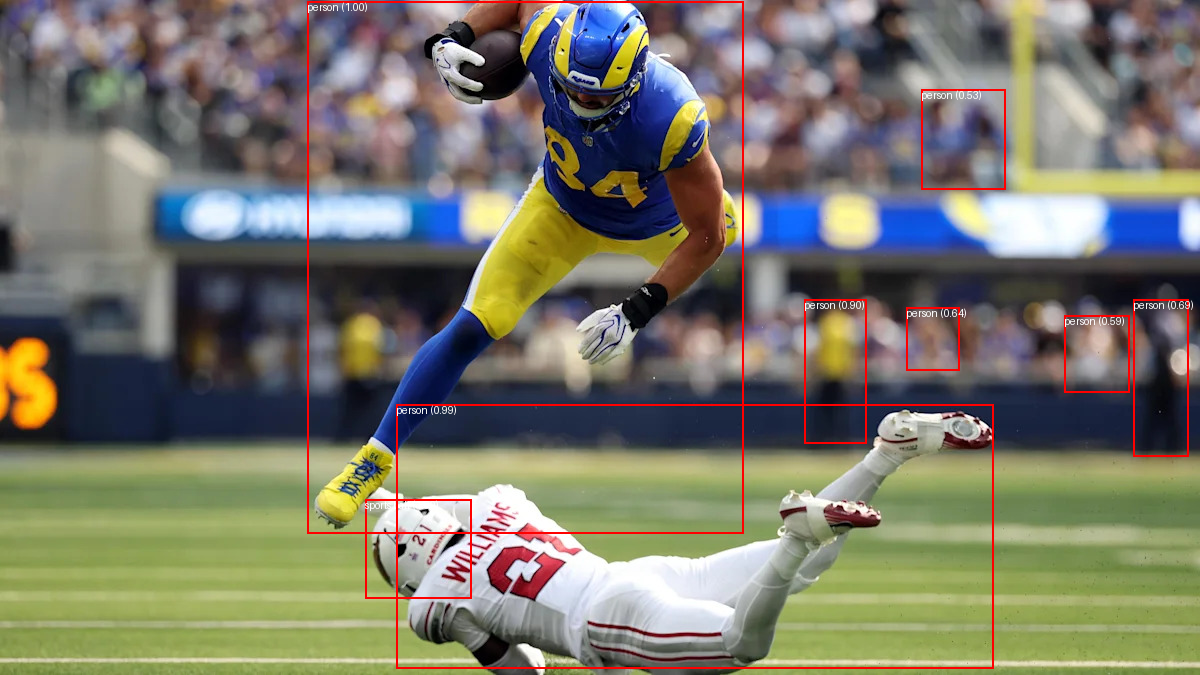


Title: Week 7 Fantasy Football Full PPR WR Rankings


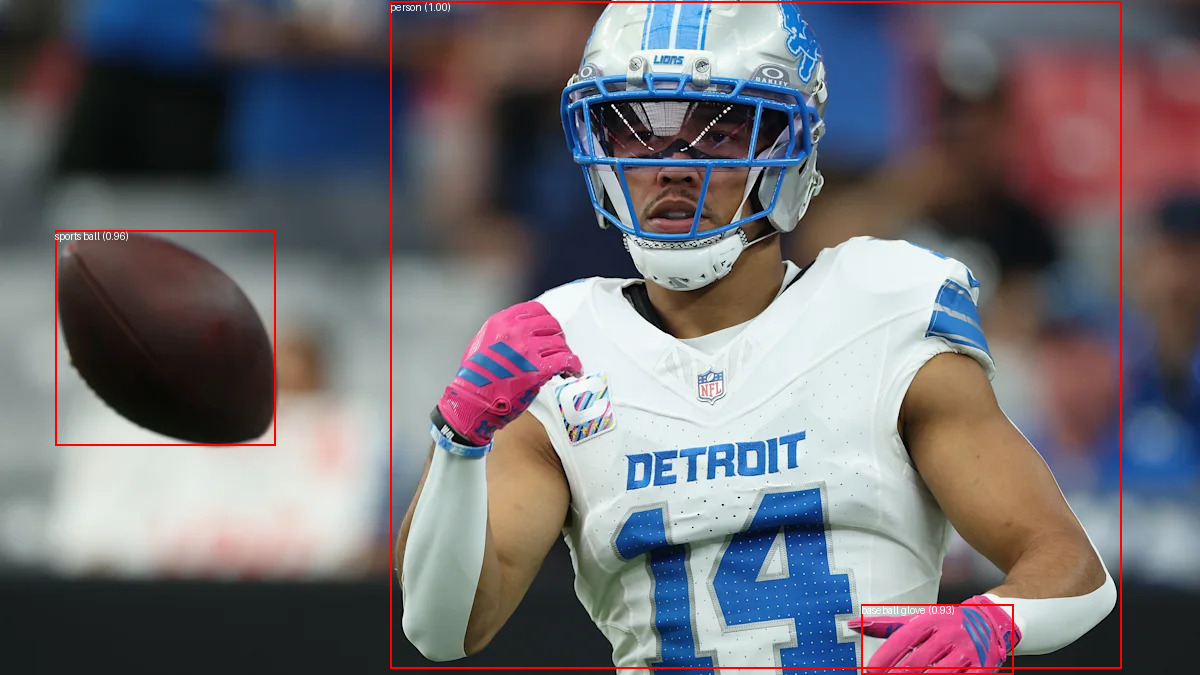


Title: Week 7 Fantasy Football Full PPR WR Rankings from Justin Boone


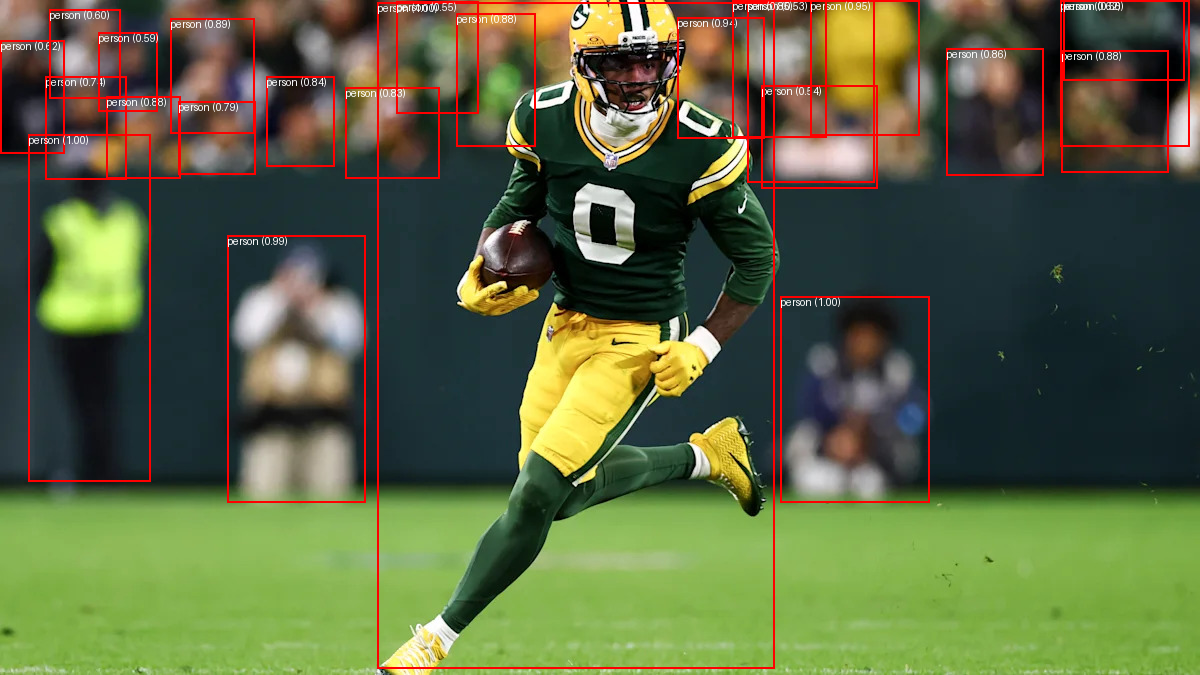

In [153]:
from IPython.display import Image
from transformers import pipeline
import requests
from PIL import Image, ImageDraw

image_urls = [
    all_articles_list[0]['urlToImage'],
    all_articles_list[1]['urlToImage'],
    all_articles_list[2]['urlToImage']
]

obj_detector = pipeline("object-detection")

for i, url in enumerate(image_urls):
    print(f"\nTitle: {all_articles_list[i]['title']}")
    try:
        image = Image.open(requests.get(url, stream=True).raw)
        results = obj_detector(image)

        draw = ImageDraw.Draw(image)
        for result in results:
            score, label, box = result["score"], result["label"], result["box"]
            x, y, x2, y2 = box['xmin'], box['ymin'], box['xmax'], box['ymax']
            draw.rectangle((x, y, x2, y2), outline="red", width=2)
            draw.text((x, y), f"{label} ({score:.2f})", fill="white")

        display(image)

    except Exception as e:
        print(f"Could not process image {i}: {e}")

**Collect statistics on what appears in the images for your news articles? What does this tell you?**

In the images for the news articles that we collected on Football, there is usually a few things in every image. Firstly there is almost always a football, and almost always someone carrying the ball. There are additionally other players or people in the background. Hugging face seems to correctly identify these; however, it seems unable to identify whether the person is a player or a spectator and identifies them as "person". It usually however can identify the football as a ball but instead of a football just labels it as a "sports ball". This tells us that this type of detection is largely general and may not be able to detect what kind of article this is. Most sports articles will have "sports balls" and "persons" in the images of the cover of the article. So in this regard it would not be able to identify what kind of sports game the article is about just that it is likely about a sports article. It may only give a high-level insight into what the article is about. A more robust verison of this may be able to tell that not only is it a football game but may even be able to tell what teams are playing and possibly even the main player in the image.

# Problem 4 (20 points): Business question

Run some additional experiments with your data to gain familiarity with the NewsAPI.

* Come up with a business question that NewsAPI data could help answer.
* Describe the business case.
* How could NewsAPI data help a company decide how to spend its resources.
* **[LLM only]** Ask your favorite LLM to provide three business ideas that this data could support and provide those ideas as part of your report.
* **[Human only]** Analyze those three ideas and come up with an idea for a product that you will form the organizing center for you work in the rest of the case studies.
* **[LLM only]**: Ask the LLM to act as a potential buyer and identify three reasons someone might not use your selected product.
* **[Human only]**: Decide which objection matters most. Propose a small experiment to test it, specify what you would measure, and define a result that would make you revise or cancel the idea.


**Business Question**

What are the most common images shown on the covers of sports News Articles from USA Today Articles?

**Business Case**

For sports reporting, the cover image is the first thing that viewers see when they click on an article. This serves as the main hook for if they want to continue reading the article. By being able to see which types of images are being shown on a website such as USA Today, including things like action images, headshots, team logos, images of teams in a huddles, this may be able to help the people who are publishing these articles determine what visuals are best suited for their respective article and which images can improve the reader retention or impressions on the article.

**How could NewsAPI data help a company decide how to spend its resources**

By using a image object detection software such as Hugging Face, a company may be able to decide how to spend its money using the metadata to determine the most effective visuals. For example, if it is found that action photos create more engagement than a company can test out more action photos on the cover of their articles to see if they get increased engagement.

**[LLM only] Ask your favorite LLM to provide three business ideas that this data could support and provide those ideas as part of your report**

*Business Idea 1*
* Sports Article Image Optimization
  * Determine which types of cover images are used most frequently.
  * This would help publishers decide what types of images to prioritize when creating articles.
* Competitor Image Strategy Analysis
  * Compare cover images used by USA Today against other major sports news publishers.
  * This would help publishers understand their competitor's visual strategies and identify opprotunities to differentiate their own articles.
* Sports Photography Resource Allocation
  * A company could use image classification to determine which sports require the most photography resources and which types of images are most frequently used for each sport
  * This would help companies decide how they should distribute their photography budgets, hire different photographers, and purchase image licenses.

**[Human only] Analyze those three ideas and come up with an idea for a product that you will form the organizing center for you work in the rest of the case studies.**

We think that the best idea for a product would be to create something that helps sports news publishers, specifically football/NFL publishers, gather information such as a chart that shows which images are best performing as compared to the cost of the resources that will be needed. This would help them to better make decisions baout how to use their budgets and increase their engagement and retention.

Our idea would be a sports image analytics tool to collect sports news articles from various sources using the NewsAPI to then use an image recognition software like we used Hugging Face in this Case Study. It would then organize the images colelcted into different categories and groups such as action images, headshots, logos, etc, as stated before.

These results will then be presented in a dashboard format so companies could use this information without having to understand all of the behind the scenes. Engagement data could also be added to these dashboards if there was a way to obtain this, which we have not yet looked into.

This would be a very useful product because it would allow companies to both increase engagement and retention while also finding ways to lower their budgets without having to worry about losing popularity in theory.

**[LLM only]: Ask the LLM to act as a potential buyer and identify three reasons someone might not use your selected product.**

*Potential Reasons a Buyer might not be interested*

* Cost of the Product
  * The cost of this product could be too expensive for smaller news publishers, especially if they already have photographers, editors, and other resources in place.
  * If the cost of using the tool is greater than the money it saves the company, it would not be worth purchasing

* Lack of Reliable Engagement Data
  * While the tool may be able to identify and categorize the images used in sports articles, it may not have access to important information such as clicks, impressions, or reader retention
  * Without this information, it would be difficult to know whether certain types of images actually perform better than others.

* Accuracy and Reliability of Image Classification
  * The image recognition software may not always correctly identify or categorize images
  * If the data is incorrect, companies may make poor decisions about their photography budgets based on misleading results

**[Human only]: Decide which objection matters most. Propose a small experiment to test it, specify what you would measure, and define a result that would make you revise or cancel the idea.**

We think that the objection that is most applicable and matters the most if the accuracyt and reliability of the image classification. If the software cannot identify the image correctly then all of the info that follows is completely useless. This means that this information will require immense testings to ensure that the classification results are correct.

To test this we could design an experiment using the 299 sports articles that we gathered, or in more detail, 100-200 sports articles from USA Today specifically that are about football or the NFL. We could then use Hugging Face to sort these images into the categories that were described above. We would then manually review each of these images to ensure that the classifications are correct, and use that as our training data. We would want to ensure that we maintain a high success rate in terms of percentages of the images that are classified correctly. For similciity sake, lets say we want a 95% accurate classification rate. We would then use this number to determine if the current model is accurate enough to move forward with creating suggestions or the dashboards. If we do not reach this number we would have to go back and improve our model in order to increase this number. Or if that still does not work we would have to start from ground zero and reconsider the idea as a whole.


In [136]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary





*-----------------
# Done

All set!

** What do you need to submit?**

* **Notebook File**: Save this IPython notebook, and find the notebook file in your folder (for example, "filename.ipynb"). This is the file you need to submit. Please make sure all the plotted tables and figures are in the notebook. If you used "ipython notebook --pylab=inline" to open the notebook, all the figures and tables should have shown up in the notebook.
**Also, you must cite any LLM assistance and any other support you get for the project.**




* **Report**: please prepare a report (less than 10 pages) to report what you found in the data.
    * What data you collected?
    * Why this topic is interesting or important to you? (Motivations)
    * How did you analyse the data?
    * What did you find in the data?


     (please include figures or tables in the report, but no source code)

* **Video**: A 2–3-minute video pitch to a Venture Capitalist. This should discuss the data you gathered, the topic of interest, the methodology you used to gather the data, and provide a preview of your product. **Submit only a link to your video, not the video file. Include the link to your video in your report file. You may upload your video to Google Drive, OneDrive, YouTube (Unlisted) or any other video-sharing platform. Ensure that anyone with the shared link can view the video without requesting access.**

Please compress the notebook file and the report (including the video link) into a zipped file and submit it on canvas.wpi.edu for grading.



# Grading Criteria:

** Total Points: 100 **


---------------------------------------------------------------------------
** Notebook results:  **
    Points: 80


    -----------------------------------
    Question 1:
    Points: 20
    -----------------------------------
    
    (1) Select a topic that you are interested in.
    Points: 6
    
    (2) Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000. Please check whether the total number of articles collected is larger than 200.)
    Points: 10
    
    
    (3) Store the articles you downloaded into a file on Google Drive (txt file or json file)
    Points: 4
    
    
    -----------------------------------
    Question 2:
    Points: 20
    -----------------------------------
    
    1. Word Count

    (1) Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
    Points: 5

    (2) Plot a table of the top 30 words with their counts
    Points: 5
    
    2. Please provide a table of the top 10 authors and sources that are the most popular among your collection.
    Points: 5
    
    3. For two popular authors or two popular sources, please compare the lexical diversity of their descriptions and contents.
    Points: 5
      
    -----------------------------------
    Question 3:
    Points: 20
    -----------------------------------
    
    (1) For each news article, download the image associated with it (using the urlToImage field).
    Points: 10

    (2) Use Hugging Face's transformers library to download a pre-trained image segmentation model.
    Points: 10
  
    -----------------------------------
    Question 4:  Business question
    Points: 20
    -----------------------------------
        Novelty: 10
        Interestingness: 10
    -----------------------------------
    Run some additional experiments with your data to gain familiarity with the NewsAPI.  Come up with a business question and describe how NewsAPI data can help you answer that question.

    -----------------------------------
    Report and video:  
    Points: 20
    -----------------------------------
    


